# 05 · Difference-in-differences
**Track 1 (local):** do PJM zones with more data center capacity see higher prices than the other zones, once gas, weather, renewables and carbon prices are taken into account?
**Track 2 (system-wide):** does PJM West move away from US hubs with few data centers after 2023?

Both use two-way fixed effects: an area effect (fixed differences between areas) and a month effect (anything that hits every area in the same month, such as a gas shock or a PJM-wide rule change). Section 2.2.2 of the thesis.

Two measures of exposure: our list (`dc_share`) and PJM's large-load adjustments (`ll_share`, zero before 2022), both divided by the zone's 2021 peak load.

In [1]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from utils import CLEAN, save_fig

zone = pd.read_parquet(CLEAN / "panel_zone_month.parquet")
hub = pd.read_parquet(CLEAN / "panel_hub_month.parquet")
zone["ll_share"] = zone.pjm_large_load_mw.fillna(0) / zone.peak_2021_mw
CONTROLS = "gas_real + hdd + cdd + renew_share + rggi_real"

## Track 1 – PJM zones
`price = β · exposure + controls + zone effect + month effect`, estimated on the all-in price and on its components. β is the change in $/MWh when data center capacity grows by 100% of the zone's 2021 peak load. Standard errors are clustered by zone.

In [2]:
models = {}

def twfe(y, x, data=zone):
    m = smf.ols(f"{y} ~ {x} + {CONTROLS} + C(zone) + C(month)", data).fit(
        cov_type="cluster", cov_kwds={"groups": data.zone.astype("category").cat.codes})
    models[y, x] = m
    lo, hi = m.conf_int().loc[x]
    return {"outcome": y, "exposure": x, "beta": m.params[x], "se": m.bse[x], "ci_low": lo, "ci_high": hi, "p": m.pvalues[x]}

rows = [twfe(y, x) for x in ["dc_share", "ll_share"]
        for y in ["wholesale_real", "lmp_real", "capacity_mwh_real", "congestion_real"]]
track1 = pd.DataFrame(rows)
track1.round(2)

,outcome,exposure,beta,se,ci_low,ci_high,p
0,wholesale_real,dc_share,56.98,6.93,43.40,70.56,0.00
1,lmp_real,dc_share,40.17,4.04,32.24,48.09,0.00
2,capacity_mwh_real,dc_share,16.81,3.01,10.91,22.71,0.00
3,congestion_real,dc_share,35.23,3.76,27.85,42.60,0.00
4,wholesale_real,ll_share,124.77,38.69,48.95,200.59,0.00
5,lmp_real,ll_share,90.52,25.32,40.89,140.15,0.00
6,capacity_mwh_real,ll_share,34.25,14.36,6.11,62.39,0.02
7,congestion_real,ll_share,81.57,21.92,38.60,124.54,0.00


**What it means for Dominion.** β × the growth of Dominion's exposure between 2019–21 and the latest 12 months: 26.9 $/MWh with our list, 22.7 with the PJM data (Table 2.4).

In [3]:
def avg(df, col, a, b):
    return df[(df.month >= a) & (df.month <= b)][col].mean()

dom = zone[zone.zone == "DOM"]
d_exp = {x: avg(dom, x, "2025-08-01", "2026-07-01") - avg(dom, x, "2019-01-01", "2021-12-01") for x in ["dc_share", "ll_share"]}
track1["dom_exposure_change"] = track1.exposure.map(d_exp)
track1["dom_usd_mwh"] = track1.beta * track1.dom_exposure_change
track1["dom_low"] = track1.ci_low * track1.dom_exposure_change
track1["dom_high"] = track1.ci_high * track1.dom_exposure_change
track1[["outcome", "exposure", "dom_exposure_change", "dom_usd_mwh", "dom_low", "dom_high"]].round(2)

,outcome,exposure,dom_exposure_change,dom_usd_mwh,dom_low,dom_high
0,wholesale_real,dc_share,0.47,26.93,20.51,33.34
1,lmp_real,dc_share,0.47,18.98,15.24,22.73
2,capacity_mwh_real,dc_share,0.47,7.94,5.16,10.73
3,congestion_real,dc_share,0.47,16.65,13.16,20.13
4,wholesale_real,ll_share,0.18,22.68,8.90,36.46
5,lmp_real,ll_share,0.18,16.46,7.43,25.48
6,capacity_mwh_real,ll_share,0.18,6.23,1.11,11.34
7,congestion_real,ll_share,0.18,14.83,7.02,22.64


## Event study: Dominion vs the other zones, year by year (2021 = 0)
If the gap is flat before the data center boom and opens only afterwards, the comparison is more credible (Figure 2.3).

,year,gap,low,high
0,2019,-2.3,-6.3,1.6
1,2020,-3.6,-8.5,1.3
0,2021,0.0,0.0,0.0
2,2022,11.7,8.2,15.3
3,2023,3.1,-0.2,6.5
4,2024,5.5,0.1,10.8
5,2025,20.7,15.2,26.2
6,2026,37.7,31.1,44.3


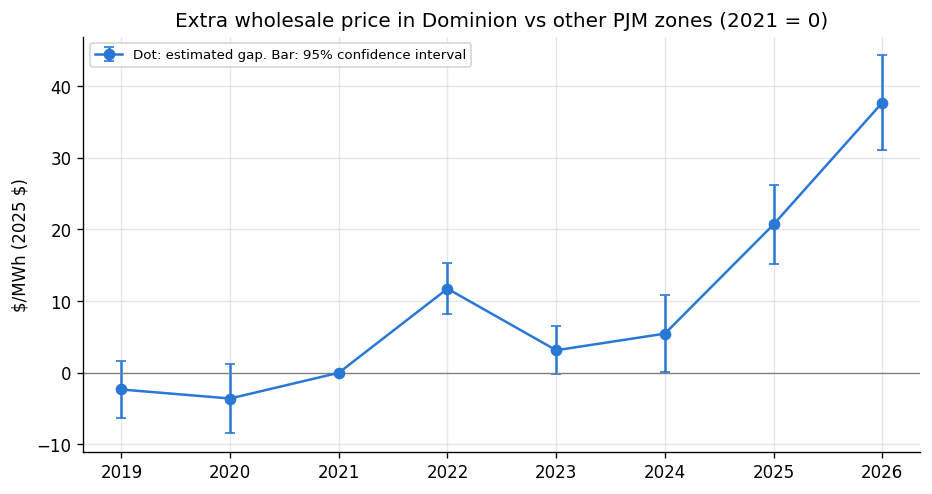

In [4]:
zone["year"] = zone.month.dt.year
YEARS = [y for y in range(2019, 2027) if y != 2021]                 # 2021 is the reference year

def event_study(df, y, unit_flag, groups, cov):
    for yr in YEARS:
        df[f"e{yr}"] = df[unit_flag] * (df.year == yr)
    terms = " + ".join(f"e{yr}" for yr in YEARS)
    m = smf.ols(f"{y} ~ {terms} + {CONTROLS} + C({groups}) + C(month)", df).fit(**cov)
    ci = m.conf_int()
    out = pd.DataFrame({"year": YEARS, "gap": [m.params[f"e{yr}"] for yr in YEARS],
                        "low": [ci.loc[f"e{yr}", 0] for yr in YEARS], "high": [ci.loc[f"e{yr}", 1] for yr in YEARS]})
    return pd.concat([out, pd.DataFrame([{"year": 2021, "gap": 0, "low": 0, "high": 0}])]).sort_values("year")

zone["dom"] = (zone.zone == "DOM").astype(int)
event1 = event_study(zone, "wholesale_real", "dom", "zone",
                     dict(cov_type="cluster", cov_kwds={"groups": zone.zone.astype("category").cat.codes}))

ax = plt.figure().gca()
ax.errorbar(event1.year, event1.gap, yerr=[event1.gap - event1.low, event1.high - event1.gap], fmt="o-", color="#2a78d6", capsize=3,
            label="Dot: estimated gap. Bar: 95% confidence interval")
ax.legend(loc="upper left", fontsize=8)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="Extra wholesale price in Dominion vs other PJM zones (2021 = 0)", ylabel="$/MWh (2025 $)")
save_fig("05_event_study_dom")
event1.round(1)

## Track 2 – PJM West vs US hubs with few data centers
`price = δ · (PJM West × after 2023) + controls + hub effect + month effect`. δ captures everything specific to PJM after 2023 that the controls do not explain; data centers are the main PJM-specific change but not the only one, so we read δ as an **upper bound**. With only 5 hubs we use heteroskedasticity-robust standard errors.

In [5]:
hub["post"] = (hub.month >= "2023-01-01").astype(int)
m2 = smf.ols(f"price_real ~ treated:post + {CONTROLS} + C(hub) + C(month)", hub).fit(cov_type="HC1")
lo, hi = m2.conf_int().loc["treated:post"]
track2 = pd.DataFrame([{"outcome": "hub price", "beta": m2.params["treated:post"], "se": m2.bse["treated:post"],
                        "ci_low": lo, "ci_high": hi, "p": m2.pvalues["treated:post"]}])
track2.round(2)

,outcome,beta,se,ci_low,ci_high,p
0,hub price,11.53,5.88,0.01,23.05,0.05


Track 2 year by year (Figure 2.6).

,year,gap,low,high
0,2019,5.3,-9.9,20.5
1,2020,2.5,-16.4,21.5
0,2021,0.0,0.0,0.0
2,2022,11.4,-14.2,37.1
3,2023,-4.2,-21.3,12.9
4,2024,11.8,-4.3,28.0
5,2025,23.8,9.6,38.0
6,2026,64.9,40.9,88.9


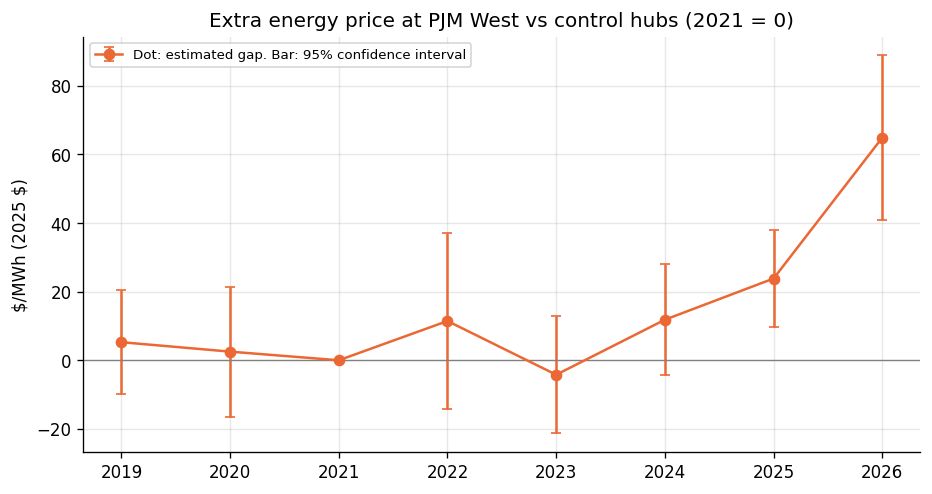

In [6]:
hub["year"] = hub.month.dt.year
event2 = event_study(hub, "price_real", "treated", "hub", dict(cov_type="HC1"))
ax = plt.figure().gca()
ax.errorbar(event2.year, event2.gap, yerr=[event2.gap - event2.low, event2.high - event2.gap], fmt="o-", color="#eb6834", capsize=3,
            label="Dot: estimated gap. Bar: 95% confidence interval")
ax.legend(loc="upper left", fontsize=8)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="Extra energy price at PJM West vs control hubs (2021 = 0)", ylabel="$/MWh (2025 $)")
save_fig("05_event_study_hubs")
event2.round(1)

## Full regression tables
All controls, fixed effects not shown (Appendix B of the thesis).

In [7]:
def coef_table(m, keep, label):
    ci = m.conf_int()
    return pd.DataFrame({"model": label, "variable": keep, "coef": m.params[keep].values, "se": m.bse[keep].values,
                         "ci_low": ci.loc[keep, 0].values, "ci_high": ci.loc[keep, 1].values, "p": m.pvalues[keep].values,
                         "n_obs": int(m.nobs), "r2": m.rsquared})

keep = ["dc_share"] + CONTROLS.split(" + ")
full = [coef_table(models[y, "dc_share"], keep, f"Track 1: {y}") for y in ["wholesale_real", "lmp_real", "capacity_mwh_real"]]
full.append(coef_table(m2, ["treated:post"] + CONTROLS.split(" + "), "Track 2: hub price"))
full = pd.concat(full)
full.to_csv(CLEAN / "regression_tables.csv", index=False)
full.round(3)

,model,variable,coef,se,ci_low,ci_high,p,n_obs,r2
0,Track 1: wholesale_real,dc_share,56.980,6.929,43.400,70.560,0.000,1820,0.946
1,Track 1: wholesale_real,gas_real,1.476,0.280,0.928,2.023,0.000,1820,0.946
2,Track 1: wholesale_real,hdd,-0.004,0.005,-0.014,0.006,0.425,1820,0.946
3,Track 1: wholesale_real,cdd,0.046,0.005,0.035,0.057,0.000,1820,0.946
4,Track 1: wholesale_real,renew_share,-40.342,45.535,-129.589,48.905,0.376,1820,0.946
5,Track 1: wholesale_real,rggi_real,0.119,0.161,-0.197,0.434,0.461,1820,0.946
0,Track 1: lmp_real,dc_share,40.167,4.043,32.244,48.091,0.000,1820,0.955
1,Track 1: lmp_real,gas_real,1.398,0.251,0.905,1.891,0.000,1820,0.955
2,Track 1: lmp_real,hdd,-0.007,0.004,-0.014,0.001,0.105,1820,0.955
3,Track 1: lmp_real,cdd,0.047,0.007,0.034,0.061,0.000,1820,0.955


## Save

In [8]:
track1.to_csv(CLEAN / "did_track1.csv", index=False)
track2.to_csv(CLEAN / "did_track2.csv", index=False)
event1.to_csv(CLEAN / "event_dom.csv", index=False)
event2.to_csv(CLEAN / "event_hubs.csv", index=False)